# Qiskit Fall Fest 2026 - Phase 1: O3 Knapsack on Processor A vs Processor B

**Selected Problem Statement: O3 - Knapsack (Quantum Optimization).**

Run this notebook **top to bottom from the repository root**. It follows the official guide order:
setup, problem, solution, Processor A, Processor B, A-vs-B comparison, interpretation, tables/figures, reproducibility.

Three rules: (1) exactly one PS, (2) controlled A/B comparison, (3) evidence first.

## 1. Setup and reproducibility

In [1]:
# Install dependencies (skip if already installed). In Colab this takes ~1 minute.
import sys, subprocess, importlib.util
if importlib.util.find_spec("qiskit_aer") is None or importlib.util.find_spec("qiskit") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"])
    print("Dependencies installed. If imports fail below, restart the runtime once and run again.")
else:
    print("Dependencies already installed.")

Dependencies already installed.


In [2]:
import os, sys, json, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import qiskit, qiskit_aer, scipy, networkx

# Make sure we are in the repository root (the folder that contains src/ and processors/).
if not (Path("src").is_dir() and Path("processors").is_dir()):
    raise RuntimeError("Run this notebook from the repository root (the folder containing src/ and processors/). "
                       f"Current folder: {os.getcwd()}")
sys.path.insert(0, os.getcwd())

from src.problem import (load_instance, brute_force, make_encoding, optimize_qaoa, build_qaoa_circuit,
                         bits_to_items, qaoa_probabilities)
from src.processors import (load_processor, build_noise_model, noise_parameters, processor_summary)
from src.routing import compile_all_to_all, run_case, compile_and_run_noisy, OPT_LEVEL
from src.metrics import (circuit_metrics, case_row, aggregate, save_table, build_report,
                         update_readme_results, df_to_markdown, solution_metrics, std_error)
from src.visualization import (plot_processor_graph, draw_circuit, plot_logical_vs_transpiled,
                               plot_ab_performance, plot_distribution, plot_tradeoffs, plot_landscape, COL_A, COL_B)

warnings.filterwarnings("ignore", category=DeprecationWarning)

# ---- global experiment configuration (identical for Processor A and B) ----
SELECTED_PS_CODE  = "O3"
SELECTED_PS_NAME  = "Knapsack"
SELECTED_TRACK    = "Quantum Optimization"
SEEDS             = [11, 12, 13, 14, 15]   # transpiler seeds (also used as simulator seeds)
SHOTS             = 4096
P_LAYERS          = 1                      # QAOA depth for the main benchmark (official baseline: shallow p=1)
LAM1, LAM2, SCALE = -3.0, 1.0, 0.2         # penalty weights and Hamiltonian scale (tuned, validated by brute force)
OPT_SEED          = 7                      # optimiser seed

RESULTS = Path("results"); TABLES = RESULTS / "tables"; FIGS = RESULTS / "figures"
for folder in (TABLES, FIGS, Path("data/processed")):
    folder.mkdir(parents=True, exist_ok=True)

print(SELECTED_PS_CODE, "-", SELECTED_PS_NAME, "|", SELECTED_TRACK)
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| python", platform.python_version())

O3 - Knapsack | Quantum Optimization
qiskit 2.5.2 | qiskit-aer 0.17.2 | python 3.13.16


## 2. Problem statement specification sheet (O3 - Knapsack)

Choose items to maximise total value without exceeding the weight capacity.

In [3]:
inst = load_instance("data/raw/knapsack_instance.json")
classical = brute_force(inst)

items_df = pd.DataFrame({"Item": inst.names, "Weight": inst.weights, "Value": inst.values})
display(items_df)
print("Capacity:", inst.capacity)
print("Exact classical optimum:", classical["best_items"],
      "| weight", classical["best_weight"], "| value", classical["best_value"],
      "| #optimal solutions:", classical["n_optimal_solutions"])
print("Top-5 feasible solutions:")
display(pd.DataFrame(classical["top5"]))

spec = pd.DataFrame({
    "Item": ["PS code", "PS name", "Track", "Input / instance", "Core algorithm", "Required output",
             "Primary metric", "Reference/classical baseline", "Processor A requirements",
             "Processor B requirements", "Architecture metrics"],
    "Value": [SELECTED_PS_CODE, SELECTED_PS_NAME, SELECTED_TRACK,
              f"{inst.n} items, capacity {inst.capacity} (data/raw/knapsack_instance.json)",
              "QAOA with unbalanced-penalization (no slack qubits) Ising encoding",
              "Best feasible item set and its value",
              "P(optimal), P(feasible), approximation ratio, Hellinger fidelity",
              f"Exact brute force: {classical['best_items']} = {classical['best_value']}",
              f"{inst.n} logical qubits fit on A", f"{inst.n} logical qubits fit on B",
              "depth, two-qubit gates, SWAPs, physical qubits, runtime"]})
display(spec)
spec.to_csv(TABLES / "ps_specification.csv", index=False)
with open("data/processed/classical_baseline.json", "w") as f:
    json.dump(classical, f, indent=2)

,Item,Weight,Value
0,A,5,10
1,B,3,4
2,C,4,7
3,D,2,5
4,E,6,8


Capacity: 15
Exact classical optimum: A+B+C+D | weight 14 | value 26 | #optimal solutions: 1
Top-5 feasible solutions:


,items,weight,value
0,A+B+C+D,14,26
1,A+C+E,15,25
2,B+C+D+E,15,24
3,A+D+E,13,23
4,A+C+D,11,22


,Item,Value
0,PS code,O3
1,PS name,Knapsack
2,Track,Quantum Optimization
3,Input / instance,"5 items, capacity 15 (data/raw/knapsack_instan..."
4,Core algorithm,QAOA with unbalanced-penalization (no slack qu...
5,Required output,Best feasible item set and its value
6,Primary metric,"P(optimal), P(feasible), approximation ratio, ..."
7,Reference/classical baseline,Exact brute force: A+B+C+D = 26
8,Processor A requirements,5 logical qubits fit on A
9,Processor B requirements,5 logical qubits fit on B


## 3. Core solution: Ising encoding and QAOA

* One qubit per item, `x_i = (1 - Z_i)/2`.
* Capacity handled with **unbalanced penalization** so no extra slack qubits are needed
  (a slack register for capacity 15 would need 4 more qubits, i.e. 9 in total, which does not fit on Processor A).
* `cost(x) = -value(x) + lam1*(C-W) + lam2*(C-W)^2`
* Every item has non-zero weight, so the cost layer needs **all pairwise ZZ interactions** (a complete graph). That is exactly what makes routing on sparse processors interesting.

In [4]:
enc = make_encoding(inst, lam1=LAM1, lam2=LAM2, scale=SCALE)   # raises an error if the Ising form is inconsistent
ground_bits = [(enc["ground_index"] >> i) & 1 for i in range(inst.n)]
print("Ground state of the encoded cost:", bits_to_items(inst, ground_bits),
      "(must equal the classical optimum:", classical["best_items"] + ")")
assert bits_to_items(inst, ground_bits) == classical["best_items"], "Encoding does not recover the optimum"

print("Ising coefficients (scaled): offset =", round(enc["offset"], 4))
print("h =", [round(x, 4) for x in enc["h"]])
print("number of ZZ couplings:", len(enc["J"]))

with open("data/processed/ising_encoding.json", "w") as f:
    json.dump({"lam1": enc["lam1"], "lam2": enc["lam2"], "scale": enc["scale"], "offset": enc["offset"],
               "h": enc["h"], "J": {f"{i}-{j}": v for (i, j), v in enc["J"].items()}}, f, indent=2)

Ground state of the encoded cost: A+B+C+D (must equal the classical optimum: A+B+C+D)
Ising coefficients (scaled): offset = 3.1
h = [4.5, 2.5, 3.5, 1.9, 5.0]
number of ZZ couplings: 10


In [5]:
# Offline parameter tuning on the exact numpy simulator (identical parameters are reused on A and B).
opt = optimize_qaoa(enc, inst.n, P_LAYERS, restarts=40, seed=OPT_SEED, objective="prob_opt")
ideal_probs = opt["ideal_probs"]
print(f"p = {P_LAYERS}: ideal probability of the optimum = {opt['ideal_prob_optimal']:.3f} "
      f"(uniform random guessing = {1/2**inst.n:.3f})")
print("gammas:", np.round(opt["gammas"], 4))
print("betas :", np.round(opt["betas"], 4))
with open("data/processed/qaoa_parameters.json", "w") as f:
    json.dump({k: v for k, v in opt.items() if k != "ideal_probs"}, f, indent=2)

p = 1: ideal probability of the optimum = 0.230 (uniform random guessing = 0.031)
gammas: [2.9441]
betas : [0.8428]


In [6]:
logical = build_qaoa_circuit(enc, inst.n, opt["gammas"], opt["betas"], measure=True)
print("Logical circuit:", circuit_metrics(logical)["operations"])
draw_circuit(logical, FIGS / "logical_circuit.png")

Logical circuit: {'rzz': 10, 'h': 5, 'rz': 5, 'rx': 5, 'measure': 5, 'barrier': 1}


PosixPath('results/figures/logical_circuit.png')

## 4. Processor definitions (A and B)

`processors/processor_A.json` and `processors/processor_B.json` **must be the official Challenge Kit files**.
If they still contain `"placeholder": true`, replace them before submitting.

,name,num_qubits,num_edges,max_degree,avg_degree,diameter,avg_shortest_path,basis_gates,one_qubit_error,two_qubit_error,readout_error,placeholder
0,processor_A,5,4,3,1.600,3,1.800,"rz,sx,x,cx",0.001,0.005,0.0,False
1,processor_B,9,12,5,2.667,4,1.944,"rz,sx,x,cx",0.001,0.005,0.0,False


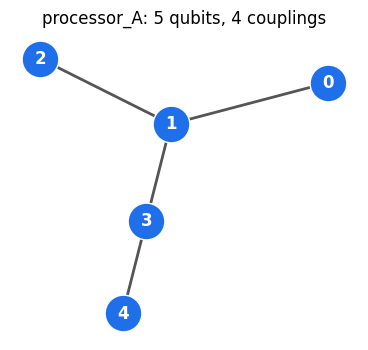

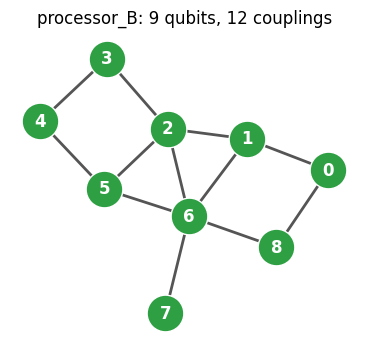

PosixPath('results/figures/processor_B_graph.png')

In [7]:
PROCS = {"A": load_processor("processors/processor_A.json"),
         "B": load_processor("processors/processor_B.json")}

for name, p in PROCS.items():
    if p.get("placeholder"):
        print(f"*** WARNING: Processor {name} is a PLACEHOLDER definition. Replace processors/processor_{name}.json "
              f"with the official Challenge Kit file before submitting. ***")
    if p["num_qubits"] < inst.n:
        raise ValueError(f"Processor {name} has only {p['num_qubits']} qubits; need {inst.n}")

summary_df = pd.DataFrame([processor_summary(PROCS["A"]), processor_summary(PROCS["B"])])
display(summary_df)
save_table(summary_df, TABLES / "processor_summary.csv")

plot_processor_graph(PROCS["A"], FIGS / "processor_A_graph.png", color=COL_A)
plot_processor_graph(PROCS["B"], FIGS / "processor_B_graph.png", color=COL_B)

## 5b. Payoff landscape (p = 1)

How good is the result for different QAOA angles? Left: exact simulation. Right: noisy simulation on Processor A
(coarse grid, fewer shots). The red star marks the best angles found.

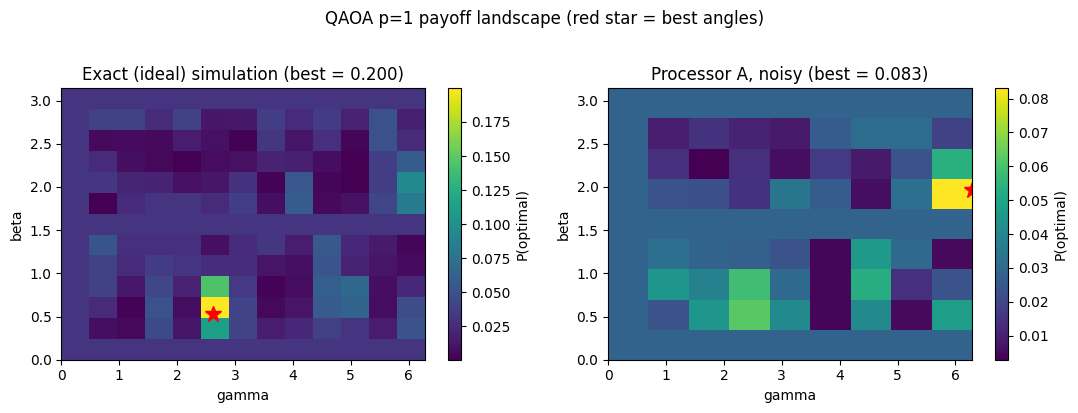

In [8]:
G = np.linspace(0, 2 * np.pi, 13)
Bt = np.linspace(0, np.pi, 13)
Z_exact = np.zeros((len(Bt), len(G)))
for bi, b in enumerate(Bt):
    for gi, g in enumerate(G):
        Z_exact[bi, gi] = qaoa_probabilities(enc["diag_scaled"], inst.n, [g], [b])[enc["ground_index"]]

G2 = np.linspace(0, 2 * np.pi, 9)
B2 = np.linspace(0, np.pi, 9)
Z_noisy = np.zeros((len(B2), len(G2)))
nm_A = build_noise_model(PROCS["A"])
for bi, b in enumerate(B2):
    for gi, g in enumerate(G2):
        circ = build_qaoa_circuit(enc, inst.n, [g], [b], measure=True)
        counts = compile_and_run_noisy(circ, PROCS["A"], SEEDS[0], 1024, nm_A)
        Z_noisy[bi, gi] = solution_metrics(counts, inst, classical, enc, ideal_probs)["prob_optimal"]
plot_landscape(G, Bt, Z_exact, Z_noisy, FIGS / "payoff_landscape.png")
pd.DataFrame(Z_noisy, index=np.round(B2, 3), columns=np.round(G2, 3)).to_csv(TABLES / "payoff_landscape_noisy_A.csv")

## 5. Controlled A/B experiment

Same logical circuit, same shots, same optimisation level, same transpiler seeds on both processors.
Each run: transpile, execute ideal (reference), execute with the processor's noise model, record metrics.

In [9]:
RUNS = {}                         # RUNS[(proc, seed)] = full result dict
ROWS = {"A": [], "B": []}         # one flat metrics row per seed

for name, proc in PROCS.items():
    for seed in SEEDS:
        res = run_case(logical, proc, seed, SHOTS)
        RUNS[(name, seed)] = res
        row = case_row(res, inst, classical, enc, ideal_probs)
        row["seed"] = seed
        ROWS[name].append(row)
    print(f"Processor {name}: {len(SEEDS)} seeds done")

AGG = {k: aggregate(v) for k, v in ROWS.items()}

for name in ("A", "B"):
    df = pd.DataFrame(ROWS[name])
    save_table(df, TABLES / f"processor_{name}_metrics.csv")
display(pd.DataFrame(ROWS["A"])[["seed", "depth", "two_qubit_gates", "swap_count", "used_physical_qubits",
                                 "noisy_prob_optimal", "noisy_prob_feasible"]])
display(pd.DataFrame(ROWS["B"])[["seed", "depth", "two_qubit_gates", "swap_count", "used_physical_qubits",
                                 "noisy_prob_optimal", "noisy_prob_feasible"]])

Processor A: 5 seeds done


Processor B: 5 seeds done


,seed,depth,two_qubit_gates,swap_count,used_physical_qubits,noisy_prob_optimal,noisy_prob_feasible
0,11,60,32,4,5,0.201660,0.850830
1,12,60,32,4,5,0.203857,0.849854
2,13,60,32,4,5,0.202637,0.846191
3,14,60,32,4,5,0.205322,0.859619
4,15,63,35,5,5,0.201660,0.862061


,seed,depth,two_qubit_gates,swap_count,used_physical_qubits,noisy_prob_optimal,noisy_prob_feasible
0,11,55,26,2,5,0.207031,0.849365
1,12,44,26,2,5,0.208496,0.857422
2,13,52,26,2,5,0.215820,0.856201
3,14,49,26,2,5,0.211182,0.858154
4,15,55,26,2,5,0.203613,0.859619


Processor A: layout (logical->physical) = [1, 3, 2, 0, 4]
  compiled ops: {'rz': 35, 'cx': 32, 'sx': 15, 'measure': 5, 'barrier': 1}


Processor B: layout (logical->physical) = [2, 5, 6, 3, 1]
  compiled ops: {'rz': 35, 'cx': 26, 'sx': 15, 'measure': 5, 'barrier': 1}


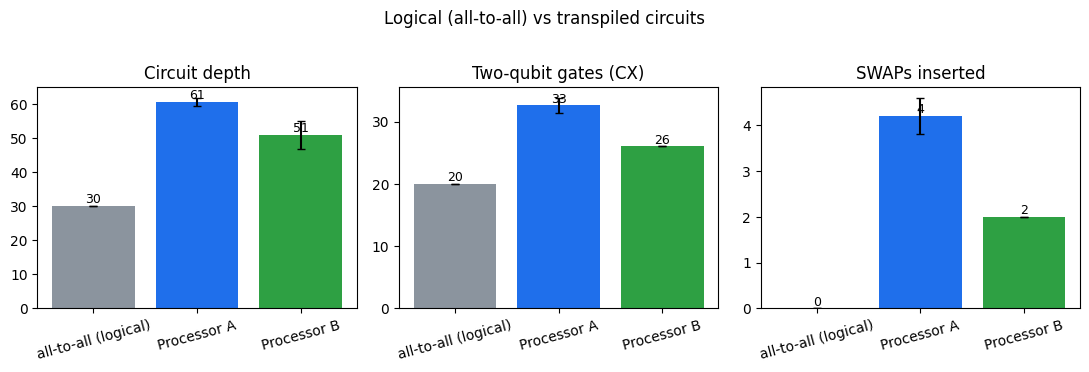

PosixPath('results/figures/logical_vs_transpiled.png')

In [10]:
# Inspect the transpiled circuits (reference seed) and compare with the all-to-all reference.
REF = SEEDS[0]
for name in ("A", "B"):
    res = RUNS[(name, REF)]
    print(f"Processor {name}: layout (logical->physical) = {res['layout']}")
    print("  compiled ops:", res["circuit_metrics"]["operations"])
    draw_circuit(res["compiled"], FIGS / f"transpiled_{name}.png")

ref_cm = circuit_metrics(compile_all_to_all(logical, PROCS["A"], REF))
ref_cm["swap_count"] = 0
ROWS_FIG = {"all-to-all (logical)": ref_cm, "Processor A": AGG["A"], "Processor B": AGG["B"]}
plot_logical_vs_transpiled(ROWS_FIG, FIGS / "logical_vs_transpiled.png")

## 6. Equal-noise control (separates connectivity from noise)

Both processors get **Processor A's error rates**. Any remaining A-vs-B difference then comes from
connectivity and the compiled circuit, not from different noise assumptions.

In [11]:
EQ_NOISE = noise_parameters(PROCS["A"])
print("Equal-noise parameters:", EQ_NOISE)
ROWS_EQ = {"A": [], "B": []}
for name, proc in PROCS.items():
    for seed in SEEDS:
        res = run_case(logical, proc, seed, SHOTS, noise_override=EQ_NOISE)
        ROWS_EQ[name].append(case_row(res, inst, classical, enc, ideal_probs))
AGG_EQ = {k: aggregate(v) for k, v in ROWS_EQ.items()}
eq_df = pd.DataFrame([{"processor": k, **{m: AGG_EQ[k][m] for m in
                       ("two_qubit_gates", "depth", "noisy_prob_optimal", "noisy_prob_feasible",
                        "noisy_hellinger_fidelity_vs_ideal")}} for k in ("A", "B")])
display(eq_df)
save_table(eq_df, TABLES / "equal_noise_control.csv")

Equal-noise parameters: {'one_qubit_error': 0.001, 'two_qubit_error': 0.005, 'readout_error': 0.0}


,processor,two_qubit_gates,depth,noisy_prob_optimal,noisy_prob_feasible,noisy_hellinger_fidelity_vs_ideal
0,A,32.6,60.6,0.203027,0.853711,0.984199
1,B,26.0,51.0,0.209229,0.856152,0.987772


PosixPath('results/tables/equal_noise_control.csv')

## 7. A vs B comparison

,Metric,Processor A,Processor B,Difference (B - A)
0,"Problem metric: P(optimal), noisy",0.203 +/- 0.001,0.209 +/- 0.004,0.006
1,"P(feasible), noisy",0.854 +/- 0.006,0.856 +/- 0.004,0.002
2,"Best sampled value / optimum, noisy",1.000 +/- 0.000,1.000 +/- 0.000,0.000
3,Approx. ratio (mean feasible value / optimum),0.631 +/- 0.005,0.635 +/- 0.006,0.003
4,Depth,60.6 +/- 1.2,51.0 +/- 4.1,-9.6
5,2Q gates (CX),32.6 +/- 1.2,26.0 +/- 0.0,-6.6
6,SWAPs,4.2 +/- 0.4,2.0 +/- 0.0,-2.2
7,Physical qubits used,5.0 +/- 0.0,5.0 +/- 0.0,0.0
8,Runtime: transpile (s),0.0166 +/- 0.0063,0.0237 +/- 0.0008,0.0072
9,Runtime: noisy simulation (s),0.0345 +/- 0.0056,0.0364 +/- 0.0039,0.0018


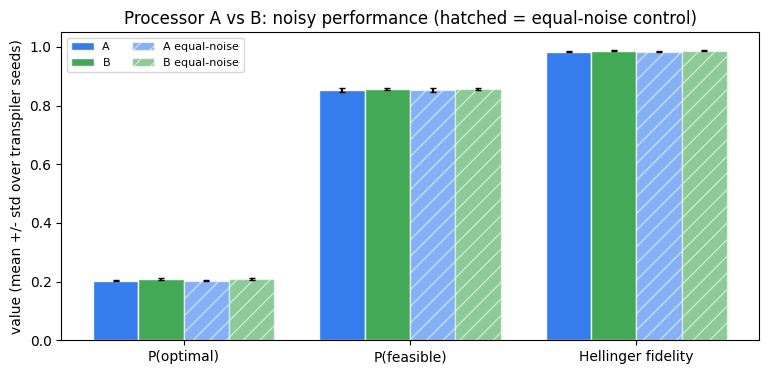

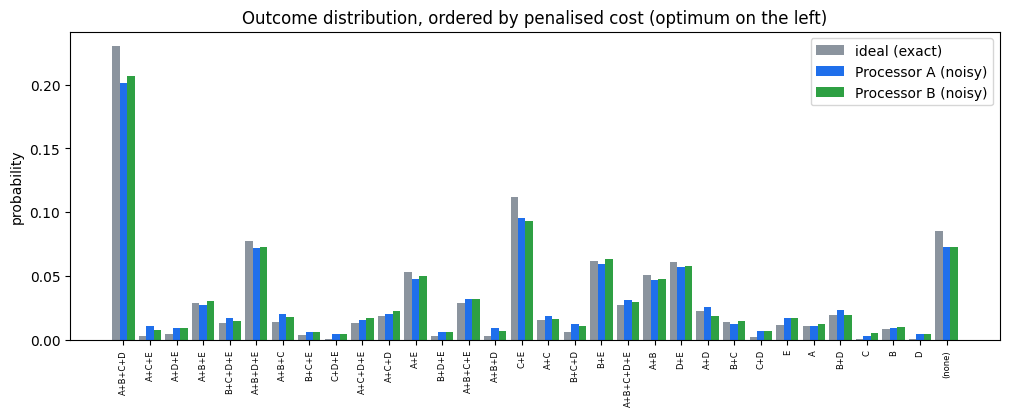

Processor A: best feasible sampled solution = A+B+C+D (value 26, optimum 26)
Processor B: best feasible sampled solution = A+B+C+D (value 26, optimum 26)


In [12]:
def mp(d, k, fmt="{:.3f}"):
    return (fmt + " +/- " + fmt).format(d[k], d.get(k + "_std", 0.0))

final_rows = [
    ("Problem metric: P(optimal), noisy", "noisy_prob_optimal", "{:.3f}"),
    ("P(feasible), noisy", "noisy_prob_feasible", "{:.3f}"),
    ("Best sampled value / optimum, noisy", "noisy_approx_ratio_best", "{:.3f}"),
    ("Approx. ratio (mean feasible value / optimum)", "noisy_approx_ratio_mean_feasible", "{:.3f}"),
    ("Depth", "depth", "{:.1f}"),
    ("2Q gates (CX)", "two_qubit_gates", "{:.1f}"),
    ("SWAPs", "swap_count", "{:.1f}"),
    ("Physical qubits used", "used_physical_qubits", "{:.1f}"),
    ("Runtime: transpile (s)", "compile_seconds", "{:.4f}"),
    ("Runtime: noisy simulation (s)", "runtime_noisy_seconds", "{:.4f}"),
    ("Fidelity: Hellinger vs ideal, noisy", "noisy_hellinger_fidelity_vs_ideal", "{:.3f}"),
]
final_df = pd.DataFrame([{
    "Metric": label,
    "Processor A": mp(AGG["A"], key, fmt),
    "Processor B": mp(AGG["B"], key, fmt),
    "Difference (B - A)": fmt.format(AGG["B"][key] - AGG["A"][key]),
} for label, key, fmt in final_rows])
display(final_df)
save_table(final_df, TABLES / "final_comparison.csv")

ab_df = pd.DataFrame([{
    "metric": key, "A_mean": AGG["A"][key], "A_std": AGG["A"].get(key + "_std", 0.0),
    "B_mean": AGG["B"][key], "B_std": AGG["B"].get(key + "_std", 0.0),
    "diff_B_minus_A": AGG["B"][key] - AGG["A"][key]} for _, key, _ in final_rows])
save_table(ab_df, TABLES / "AB_comparison.csv")

plot_ab_performance(AGG, AGG_EQ, FIGS / "AB_performance.png")
plot_distribution(inst, enc, ideal_probs, RUNS[("A", REF)]["noisy_counts"], RUNS[("B", REF)]["noisy_counts"],
                  FIGS / "outcome_distribution.png")

BEST_ITEMS = {}
for name in ("A", "B"):
    sm = solution_metrics(RUNS[(name, REF)]["noisy_counts"], inst, classical, enc, ideal_probs)
    BEST_ITEMS[name] = sm["best_feasible_items"]
    print(f"Processor {name}: best feasible sampled solution = {sm['best_feasible_items']} "
          f"(value {sm['best_feasible_value']}, optimum {classical['best_value']})")

## 8. QAOA depth sweep (quality vs circuit cost)

More QAOA layers raise the ideal success probability but add two-qubit gates, and under noise that costs quality.
Parameters are re-tuned for each p on the ideal simulator; the same parameters are used on A and B.

,p,ideal_prob_optimal,A_two_qubit_gates,A_depth,A_swap_count,A_noisy_prob_optimal,B_two_qubit_gates,B_depth,B_swap_count,B_noisy_prob_optimal
0,1,0.230224,32.000000,60.000000,4.0,0.202718,26.000000,50.333333,2.000000,0.210449
1,2,0.433987,70.000000,110.333333,10.0,0.326090,53.333333,92.000000,4.666667,0.350098
2,3,0.455936,110.333333,158.000000,17.0,0.304769,84.666667,138.000000,8.666667,0.335693


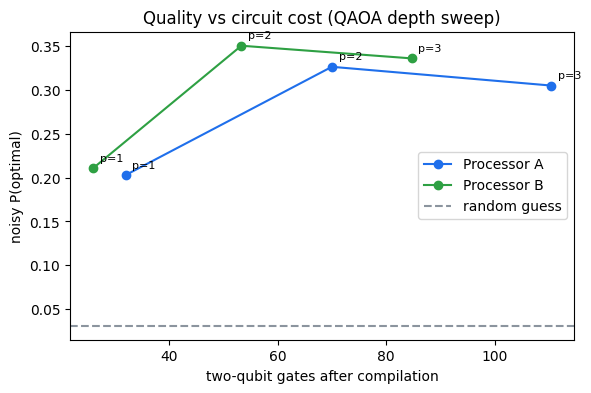

PosixPath('results/figures/architecture_tradeoffs.png')

In [13]:
SWEEP_P = [1, 2, 3]
SWEEP_SEEDS = SEEDS[:3]
sweep = []
for p in SWEEP_P:
    o = optimize_qaoa(enc, inst.n, p, restarts=40, seed=OPT_SEED, objective="prob_opt")
    circ = build_qaoa_circuit(enc, inst.n, o["gammas"], o["betas"], measure=True)
    rec = {"p": p, "ideal_prob_optimal": o["ideal_prob_optimal"]}
    for name, proc in PROCS.items():
        rows = [case_row(run_case(circ, proc, s, SHOTS), inst, classical, enc, o["ideal_probs"])
                for s in SWEEP_SEEDS]
        a = aggregate(rows)
        rec[f"{name}_two_qubit_gates"] = a["two_qubit_gates"]
        rec[f"{name}_depth"] = a["depth"]
        rec[f"{name}_swap_count"] = a["swap_count"]
        rec[f"{name}_noisy_prob_optimal"] = a["noisy_prob_optimal"]
    sweep.append(rec)
sweep_df = pd.DataFrame(sweep)
display(sweep_df)
save_table(sweep_df, TABLES / "depth_sweep.csv")
plot_tradeoffs(sweep, FIGS / "architecture_tradeoffs.png")

## 9. Protection / error detection

The parity-check and syndrome-postselection study belongs to the Bell-correlation challenge (offline Phase 2).
Phase 1 stops at the Processor A/B comparison, so it is intentionally not part of this notebook.

## 10. Reproducibility record, report and README

In [14]:
run_config = {
    "selected_ps": f"{SELECTED_PS_CODE} - {SELECTED_PS_NAME}", "track": SELECTED_TRACK,
    "instance": inst.name, "shots": SHOTS, "transpiler_seeds": SEEDS, "optimization_level": OPT_LEVEL,
    "qaoa_layers": P_LAYERS, "lam1": LAM1, "lam2": LAM2, "scale": SCALE, "optimizer_seed": OPT_SEED,
    "equal_noise_parameters": EQ_NOISE,
    "processors": {k: {"num_qubits": v["num_qubits"], "coupling_map": v["coupling_map"],
                       "basis_gates": v["basis_gates"], "noise": v.get("noise"),
                       "placeholder": bool(v.get("placeholder", False))} for k, v in PROCS.items()},
    "versions": {"python": platform.python_version(), "qiskit": qiskit.__version__,
                 "qiskit_aer": qiskit_aer.__version__, "numpy": np.__version__, "scipy": scipy.__version__,
                 "pandas": pd.__version__, "networkx": networkx.__version__},
}
with open(TABLES / "run_config.json", "w") as f:
    json.dump(run_config, f, indent=2)

qaoa_info = {k: v for k, v in opt.items() if k != "ideal_probs"}
qaoa_info.update({"lam1": enc["lam1"], "lam2": enc["lam2"]})
ctx = {"inst": inst, "classical": classical, "agg": AGG, "agg_equal": AGG_EQ, "qaoa": qaoa_info,
       "config": {"shots": SHOTS, "opt_level": OPT_LEVEL, "seeds": SEEDS}, "proc": PROCS,
       "best_items": BEST_ITEMS, "depth_sweep": sweep, "reference": ref_cm}

report_md = build_report(ctx)
Path("report.md").write_text(report_md, encoding="utf-8")

readme_block = ("**Problem:** " + f"{inst.n} items, capacity {inst.capacity}; exact optimum {classical['best_items']} "
                f"(value {classical['best_value']}). QAOA p={P_LAYERS}, {SHOTS} shots, {len(SEEDS)} transpiler seeds.\n\n"
                + df_to_markdown(final_df) + "\n")
if any(p.get("placeholder") for p in PROCS.values()):
    readme_block = "> **WARNING: placeholder processor definitions were used. Re-run with the official files.**\n\n" + readme_block
update_readme_results("README.md", readme_block)
print("report.md and README.md updated.")
print(report_md[:2500])

report.md and README.md updated.
# Phase 1 Report - O3 Knapsack

## 1. Problem

Selected Problem Statement: **O3 - Knapsack** (track: Quantum Optimization). Capacity = 15. Items: A (w=5, v=10); B (w=3, v=4); C (w=4, v=7); D (w=2, v=5); E (w=6, v=8).

Exact classical baseline (brute force over 32 subsets): optimum = **A+B+C+D**, weight 14, value **26** (1 optimal solution(s), 28 feasible subsets).

## 2. Method

* Encoding: one qubit per item (5 qubits), unbalanced penalization with no slack qubits: cost(x) = -value(x) + -3.0*(C-W) + 1.0*(C-W)^2, mapped to an Ising Hamiltonian (all-to-all ZZ couplings because every item has non-zero weight).
* Algorithm: QAOA with p = 1 layers. Parameters were tuned offline on an exact numpy simulator (objective: prob_opt) and reused unchanged on both processors. Ideal probability of the optimum = 0.230 (random guessing = 0.031).
* Controlled benchmark: same circuit, 4096 shots, transpiler optimization level 1, 5 transpiler seeds ([11, 12, 13, 14, 15]);

In [15]:
# Final sanity check of the required repository layout.
required = ["README.md", "main.ipynb", "requirements.txt", "data/raw", "data/processed",
            "processors/processor_A.json", "processors/processor_B.json",
            "src/__init__.py", "src/problem.py", "src/processors.py", "src/routing.py", "src/metrics.py",
            "src/visualization.py", "results/tables", "results/figures", "report.md",
            "assets/qff_phase1_latex_images"]
missing = [r for r in required if not Path(r).exists()]
print("Missing items:", missing if missing else "none - layout complete")
print("Tables :", sorted(p.name for p in TABLES.iterdir()))
print("Figures:", sorted(p.name for p in FIGS.iterdir()))

Missing items: none - layout complete
Tables : ['AB_comparison.csv', 'depth_sweep.csv', 'equal_noise_control.csv', 'final_comparison.csv', 'payoff_landscape_noisy_A.csv', 'processor_A_metrics.csv', 'processor_B_metrics.csv', 'processor_summary.csv', 'ps_specification.csv', 'run_config.json']
Figures: ['AB_performance.png', 'architecture_tradeoffs.png', 'logical_circuit.png', 'logical_vs_transpiled.png', 'outcome_distribution.png', 'payoff_landscape.png', 'processor_A_graph.png', 'processor_B_graph.png', 'transpiled_A.png', 'transpiled_B.png']


## 11. Participant lab notes

**Problem Statement.** O3 Knapsack: maximise value under a weight capacity.

**Method.** QAOA with an unbalanced-penalization Ising encoding (5 qubits, no slack), parameters tuned offline.

**Processor A / B.** See `results/tables/processor_A_metrics.csv` and `processor_B_metrics.csv`.

**A vs B, explanation, evidence, limitations.** Written automatically from measured numbers in `report.md`
(sections 3-6). Read it and add your own commentary in `report.md` after the run if you want to go deeper.

### Submission checklist
- [ ] Exactly one PS (O3) clearly documented
- [ ] Official processor_A.json / processor_B.json in `processors/` (no `placeholder` keys)
- [ ] Notebook runs top to bottom from a clean environment
- [ ] `results/tables`, `results/figures`, `report.md`, `README.md` regenerated by that run
- [ ] Repository is accessible to judges; AI assistance disclosed